In [ ]:
import pandas as pd
import numpy as np
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostClassifier
import json
from sklearn.ensemble import VotingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

In [6]:
# ==============================================================================
# 1. LOAD, MERGE & CLEAN DATA (NO CLUSTERING)
# ==============================================================================
print("Loading Champion Dataset (Top 200) and HMM Features...")

X_top200 = pd.read_parquet('../data/processed/features_top200.parquet')
X_hmm = pd.read_parquet('../data/processed/features_hmm.parquet')

X_combined = X_top200.join(X_hmm)

# Drop Cluster_ID as decided in our ablation study
if 'Cluster_ID' in X_combined.columns:
    X_combined = X_combined.drop(columns=['Cluster_ID'])

# Load Target
y_train = pd.read_parquet('../data/raw/y_train.parquet')
y = y_train.loc[X_combined.index]['structural_breakpoint']

imbalance_ratio = float((y == 0).sum() / (y == 1).sum())
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print(f"Initial Features shape: {X_combined.shape}")

Loading Champion Dataset (Top 200) and HMM Features...
Initial Features shape: (10001, 206)



PHASE 1: FEATURE IMPORTANCE RANKING
Training Base XGBoost to evaluate features...

Top 10 Most Important Features:
                                                               Feature  Importance
                                                  hmm_post_ll_per_step    0.019686
                                           value__quantile__q_0.2_full    0.019149
cumsum_period__agg_autocorrelation__f_agg_"mean"__maxlag_40_cumsum_pre    0.018749
           value__percentage_of_reoccurring_values_to_all_values_ratio    0.013524
                                                         magic_cv_full    0.012619
                  value__ratio_value_number_to_time_series_length_diff    0.011972
                                             value__has_duplicate_full    0.011604
                                           value__quantile__q_0.4_full    0.011211
value__change_quantiles__f_agg_"mean"__isabs_True__qh_0.8__ql_0.4_full    0.010689
                                                      

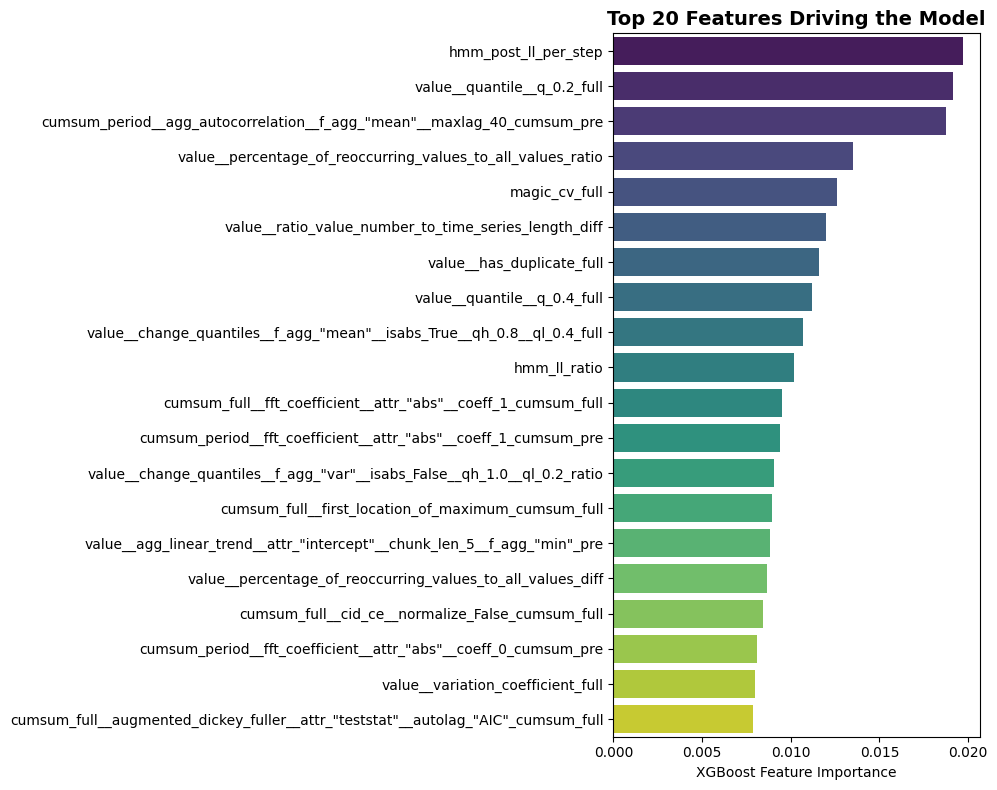

In [7]:
# ==============================================================================
# 2. FEATURE SELECTION (FINDING THE TRUE SIGNAL)
# ==============================================================================
print("\n" + "="*60)
print("PHASE 1: FEATURE IMPORTANCE RANKING")
print("="*60)

# Train a fast, generic XGBoost to evaluate feature importance
print("Training Base XGBoost to evaluate features...")
selector_model = xgb.XGBClassifier(
    n_estimators=300, 
    learning_rate=0.05, 
    max_depth=6,
    scale_pos_weight=imbalance_ratio,
    eval_metric='auc',
    random_state=42,
    n_jobs=-1
)

selector_model.fit(X_combined, y)

# Extract and sort feature importances
importances = selector_model.feature_importances_
feature_names = X_combined.columns

feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Keep the N features
TOP_N_FEATURES = 75
top_features = feature_importance_df.head(TOP_N_FEATURES)['Feature'].tolist()

print("\nTop 10 Most Important Features:")
print(feature_importance_df.head(10).to_string(index=False))

# Create the new purified dataset
X_purified = X_combined[top_features]
X_purified.columns = X_purified.columns.str.replace(r'[^\w\s]', '_', regex=True)
print(f"\nPurified Features shape: {X_purified.shape}")

# Visualizing Top 20 Features
plt.figure(figsize=(10, 8))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df.head(20), palette='viridis')
plt.title('Top 20 Features Driving the Model', fontsize=14, fontweight='bold')
plt.xlabel('XGBoost Feature Importance')
plt.ylabel('')
plt.tight_layout()
plt.show()


PHASE 2: EVALUATING ENSEMBLE ON TOP 75 FEATURES
Target to beat: 0.7872
Executing 5-Fold CV on the Purified Dataset (75 features)...

FINAL ENSEMBLE ROC AUC (PURIFIED DATA): 0.7933


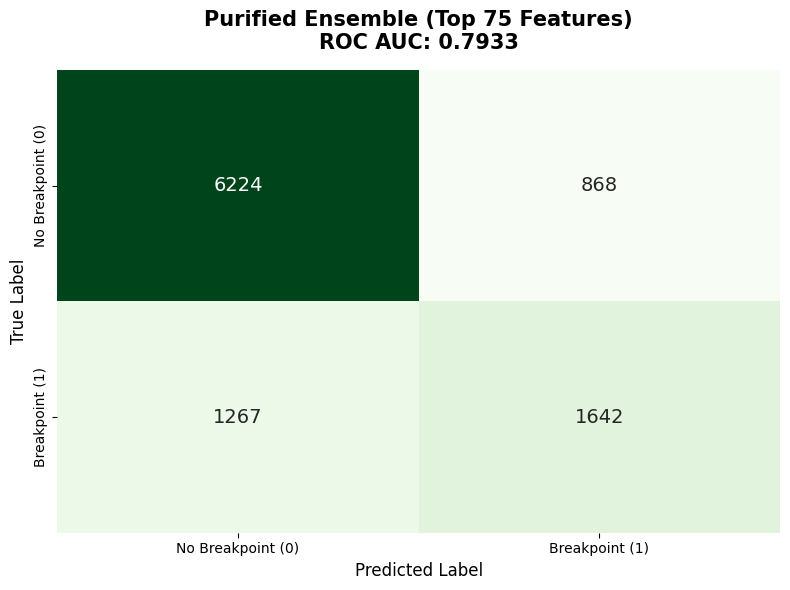

In [8]:
# ==============================================================================
# 3. EVALUATING THE ENSEMBLE ON PURIFIED DATA
# ==============================================================================
print("\n" + "="*60)
print(f"PHASE 2: EVALUATING ENSEMBLE ON TOP {TOP_N_FEATURES} FEATURES")
print("Target to beat: 0.7872")
print("="*60)

xgb_params = {
    'n_estimators': 350,
    'learning_rate': 0.05,
    'max_depth': 6,
    'subsample': 0.8,
    'colsample_bytree': 0.8,
    'min_child_weight': 3,
    'gamma': 0.1,
    'scale_pos_weight': imbalance_ratio, 
    'eval_metric': 'auc', 
    'random_state': 42, 
    'n_jobs': -1
}

lgb_params = {
    'n_estimators': 350,
    'learning_rate': 0.05,
    'max_depth': 6,
    'num_leaves': 31,
    'min_child_samples': 20,
    'subsample': 0.8,
    'colsample_bytree': 0.8,
    'scale_pos_weight': imbalance_ratio, 
    'random_state': 42, 
    'n_jobs': -1, 
    'verbose': -1
}

final_xgb = xgb.XGBClassifier(**xgb_params)
final_lgb = lgb.LGBMClassifier(**lgb_params)
final_cat = CatBoostClassifier(
    iterations=400, learning_rate=0.05, depth=6,
    scale_pos_weight=imbalance_ratio, eval_metric='AUC',
    random_state=42, verbose=0, thread_count=-1
)

final_ensemble = VotingClassifier(
    estimators=[('xgb', final_xgb), ('lgb', final_lgb), ('cat', final_cat)],
    voting='soft', n_jobs=1
)

print(f"Executing 5-Fold CV on the Purified Dataset ({TOP_N_FEATURES} features)...")
final_scores = cross_val_score(final_ensemble, X_purified, y, cv=cv_strategy, scoring='roc_auc', n_jobs=1)
mean_final_auc = np.mean(final_scores)

print(f"\nFINAL ENSEMBLE ROC AUC (PURIFIED DATA): {mean_final_auc:.4f}")

# Plot Confusion Matrix
y_pred_proba = cross_val_predict(final_ensemble, X_purified, y, cv=cv_strategy, method='predict_proba', n_jobs=1)[:, 1]
y_pred_bin = (y_pred_proba >= 0.5).astype(int)
cm = confusion_matrix(y, y_pred_bin)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', cbar=False,
            xticklabels=['No Breakpoint (0)', 'Breakpoint (1)'],
            yticklabels=['No Breakpoint (0)', 'Breakpoint (1)'],
            annot_kws={"size": 14})
plt.title(f'Purified Ensemble (Top {TOP_N_FEATURES} Features)\nROC AUC: {mean_final_auc:.4f}', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.tight_layout()
plt.show()

In [9]:
# ==============================================================================
# 4. SAVE THE PURIFIED DATASET AND THE FEATURE LIST
# ==============================================================================
print("\nSaving purified dataset to disk...")
X_purified.to_parquet('../data/processed/features_top75.parquet')

# Save the list of feature names as a JSON for the submission script later
with open('../data/processed/top75_features_list.json', 'w') as f:
    json.dump(top_features, f)

print("Saved 'features_top75.parquet'")
print("Saved 'top75_features_list.json'")


Saving purified dataset to disk...
Saved 'features_top75.parquet'
Saved 'top75_features_list.json'
